<a href="https://colab.research.google.com/github/muhammad-usman-tech/data-analysis-tasks/blob/main/Task_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
df_2015=pd.read_csv('/content/2015.csv')
df_2017=pd.read_csv('/content/2017.csv')
# df_2015.info()
print('======================')
# df_2017.info()

df_2017=df_2017.rename(
    columns={
        'Happiness.Rank': 'Happiness Rank',
        'Happiness.Score':'Happiness Score',
        'Economy..GDP.per.Capita.':'Economy (GDP per Capita)',
        'Health..Life.Expectancy.':'Health (Life Expectancy)',
        'Trust..Government.Corruption.':'Trust (Government Corruption)',
        'Dystopia.Residual':'Dystopia Residual'
    })

df_2017['Year']='2017'
df_2015['Year']='2015'

df=pd.concat([df_2015,df_2017])
df.info()

# 34
df.groupby('Region').agg(
    MAX_Score=("Happiness Score",'max'),
    MIN_SCORE=('Happiness Score','min'),
    AVG_SCORE=('Happiness Score','mean'),
)
# now by year 35
df.groupby('Year')['Happiness Score'].mean().sort_values(ascending=False)



# 36
df.groupby('Region').agg(
    Max_capita=('Economy (GDP per Capita)','max'),
    Min_capita=('Economy (GDP per Capita)','min'),
    Mean_capita=('Economy (GDP per Capita)','mean'),
    Count_capita=('Economy (GDP per Capita)','count')
) # i think the count is givving the number of capita appearing with that region



# 37
pivot_data=df.pivot_table(
    index='Region',
    columns='Year',
    aggfunc='mean',
    values='Happiness Score'
)
pivot_data

# 38 i am supposed to make the recent years so seprating the years
df_205=df[df['Year']=='2015']
df_205=df_205.sort_values(by='Happiness Score',ascending=False)
# top 5 happiest in the 2015
df_205['Country'].head()
# least 5 happiest in the 2015
df_205['Country'].tail()


df_207=df[df['Year']=='2017']
df_207=df_207.sort_values(by='Happiness Score',ascending=False)
# top 5 happiest in the 2017
df_207['Country'].head()
# least 5 happiest in the 2017
df_207['Country'].tail()

39
pivot_data.to_csv(' happiness_pivot.csv',index=False)

df.to_csv('happiness.csv')




<class 'pandas.core.frame.DataFrame'>
Index: 313 entries, 0 to 154
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        313 non-null    object 
 1   Region                         158 non-null    object 
 2   Happiness Rank                 313 non-null    int64  
 3   Happiness Score                313 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       313 non-null    float64
 6   Family                         313 non-null    float64
 7   Health (Life Expectancy)       313 non-null    float64
 8   Freedom                        313 non-null    float64
 9   Trust (Government Corruption)  313 non-null    float64
 10  Generosity                     313 non-null    float64
 11  Dystopia Residual              313 non-null    float64
 12  Year                           313 non-null    object 


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

df=pd.read_csv('/content/happiness.csv',index_col=0)
df.head()
# 41
df.describe()
# 42

print('Happiness_Score_Mean :',df['Happiness Score'].mean())
print('Happiness_Score_Median : ',df['Happiness Score'].median())
print('Happiness_Score_Mode : ',df['Happiness Score'].mode())
print('Happiness_Score_STD',df['Happiness Score'].std())


# 43
max_year=df['Year'].max()
df_max=df[df['Year']==max_year]


print('===========================')
print('MAX',df.loc[df_max['Happiness Score'].idxmax(),'Country'])
print('Min',df.loc[df_max['Happiness Score'].idxmin(),'Country'])
print('===========================')
# 44
df['Country'].nunique()
df['Region'].nunique()

# 45

filter=df[df['Happiness Score'] >=7.0]
filter['Country'].nunique() #15 countries with the score greater then 7.0

# 46
df.groupby('Region')['Economy (GDP per Capita)'].sum().sort_values(ascending=False)
# Central and Eastern Europe got the top


# 47
new=df.describe()
new.to_csv('new.csv')


Happiness_Score_Mean : 5.364980831134052
Happiness_Score_Median :  5.26900005340576
Happiness_Score_Mode :  0    5.074
1    5.192
2    5.838
3    6.454
4    7.284
Name: Happiness Score, dtype: float64
Happiness_Score_STD 1.1364339417762006
MAX 0    Switzerland
0         Norway
Name: Country, dtype: object
Min 154                       Benin
154    Central African Republic
Name: Country, dtype: object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Date                    188 non-null    object 
 1   Confirmed               188 non-null    int64  
 2   Deaths                  188 non-null    int64  
 3   Recovered               188 non-null    int64  
 4   Active                  188 non-null    int64  
 5   New cases               188 non-null    int64  
 6   New deaths              188 non-null    int64  
 7   New recovered           188 non-null    int64  
 8   Deaths / 100 Cases      188 non-null    float64
 9   Recovered / 100 Cases   188 non-null    float64
 10  Deaths / 100 Recovered  188 non-null    float64
 11  No. of countries        188 non-null    int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 17.8+ KB


/tmp/ipykernel_1932/1024967886.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


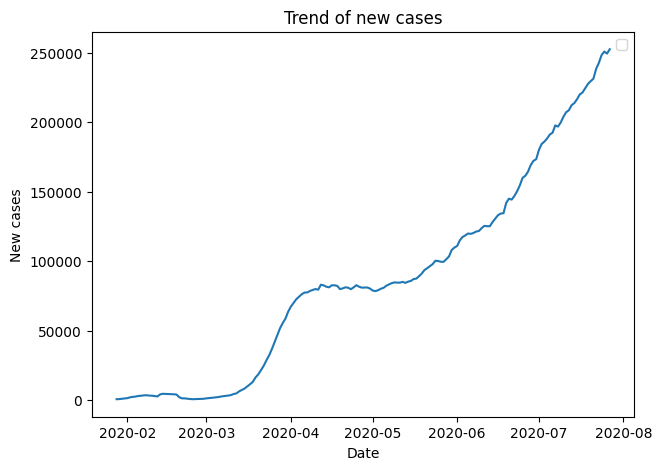

peak_date:  2020-07-23 00:00:00


In [35]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 48
df=pd.read_csv('/content/day_wise.csv')
df.info()
# df.head()

# 49 firstly it already has the index column but we have to make the date as a index column and i guess parsing means to cnvert into its real date time datatype
df['Date']=pd.to_datetime(df['Date'],format='mixed')
df['Year']=df['Date'].dt.year
df['Year'].value_counts() #have only one year can go with the days here

df.set_index('Date',inplace=True) #i think its done as the index

# 50 Filter the data to include only three countries of your choice (e.g., USA, India, Germany)

# df['Country'] this data set does not have any country column infact it has number of countries

# 51. For each selected country, calculate the 7-day rolling average of new daily cases.
# definately we don't have the countries
# so can find the 7 day rolling avg of the whole df
df=df.sort_values(by='Date',ascending=True)
avg_rolling=df['New cases'].rolling(7).mean()
avg_rolling.head(15)


#-52
#  Calculate cumulative total cases and deaths for each selected country over time.
# again don't have country so just going through the all the data frame
# as the data set is sorted according to the time
# and i think in the total cases the active or the new cases can come
comu_totalcases=df['New cases'].cumsum()
comu_totalcases.head(15)
commu_death=df['Deaths'].cumsum()
commu_death.head(13)


#  53 Identify the date of peak daily cases for each country.
# again for the each country not possible i am gonna do it for the all

# i want peak daily cases index and already the index in the date setted

peak_date=df['New cases'].idxmax()
 #we got 2020-07-23
# 54 Create a line plot showing the 7-day rolling average of new cases for all three countries on the
# same chart. Add a title, axis labels, and a legend.
# if i will create it for whole data frame it is gonna too long and big and irrelevat
# but i can try it

plt.figure(figsize=(7,5))
sns.lineplot(avg_rolling)
plt.title('Trend of new cases')
plt.xlabel('Date')
plt.ylabel('New cases')
plt.legend()
plt.show()


# that plot is little not understandable for me because in the xlabel it is shwing me the dates as 0, then 25 then 50 then 75 then 100 then 125

# but if i talk about the interpretation the cases were in moderate from date 25 to 50 then it moved up at from the 50 and 75 to 125 moderate and then went up and now at the 175 at its peak

# but i promise i will search the covid data frame with the countries and then do the data filtering and the slicing in there


print('=========')
print('peak_date: ',peak_date)
